In [1]:
# Import library yang dibutuhkan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Memuat dataset Breast Cancer Wisconsin
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

# Menampilkan 5 baris pertama
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### B1. Deskripsi Dataset

Dataset Breast Cancer Wisconsin berasal dari dataset bawaan library Scikit-learn. Dataset ini digunakan untuk mengklasifikasikan tumor payudara menjadi dua kelas, yaitu malignant (ganas) dan benign (jinak). Dataset memiliki 569 baris, 30 fitur numerik, dan satu variabel target bernama `target`. Target bernilai 0 menunjukkan malignant, sedangkan target bernilai 1 menunjukkan benign.

In [2]:
# Memeriksa ukuran dan informasi dataset
print("Jumlah baris dan kolom:", df.shape)

print("\nInformasi dataset:")
df.info()

# Memeriksa missing values
print("\nMissing values setiap kolom:")
print(df.isnull().sum())

# Memeriksa data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())

# Statistik deskriptif
df.describe()

Jumlah baris dan kolom: (569, 31)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               5

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


### B2. Eksplorasi dan Visualisasi Data

Eksplorasi dilakukan untuk memahami distribusi kelas target, perbedaan karakteristik fitur numerik pada setiap kelas, serta hubungan antarfitur. Tiga visualisasi yang digunakan adalah bar chart distribusi kelas target, box plot fitur berdasarkan kelas, dan heatmap korelasi.

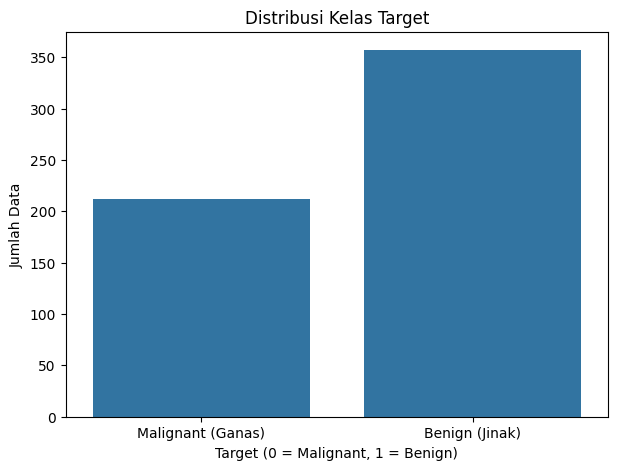

Jumlah setiap kelas:
target
0    212
1    357
Name: count, dtype: int64


In [3]:
# Visualisasi 1: Distribusi kelas target
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='target')

plt.title('Distribusi Kelas Target')
plt.xlabel('Target (0 = Malignant, 1 = Benign)')
plt.ylabel('Jumlah Data')
plt.xticks([0, 1], ['Malignant (Ganas)', 'Benign (Jinak)'])
plt.show()

# Menampilkan jumlah setiap kelas
print("Jumlah setiap kelas:")
print(df['target'].value_counts().sort_index())

**Interpretasi Visualisasi 1: Distribusi Kelas Target**

Grafik menunjukkan bahwa terdapat 212 data tumor ganas (malignant) dan 357 data tumor jinak (benign). Jumlah kedua kelas tidak seimbang karena kelas benign memiliki jumlah data lebih banyak. Ketidakseimbangan ini perlu diperhatikan saat melatih dan mengevaluasi model agar model tidak hanya baik dalam memprediksi kelas mayoritas.

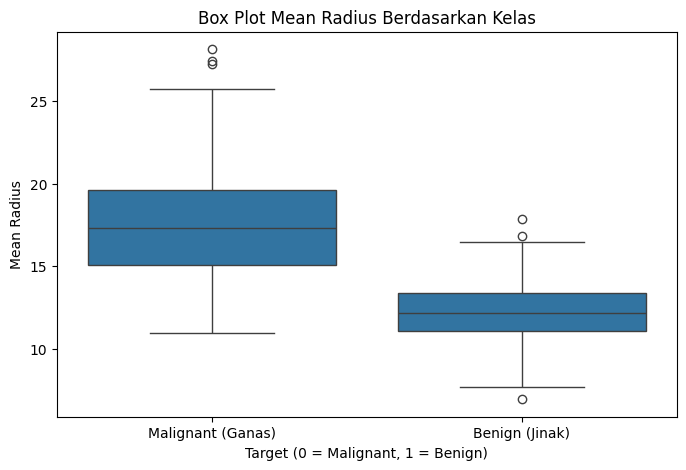

In [4]:
# Visualisasi 2: Box plot fitur berdasarkan kelas
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='target',
    y='mean radius'
)

plt.title('Box Plot Mean Radius Berdasarkan Kelas')
plt.xlabel('Target (0 = Malignant, 1 = Benign)')
plt.ylabel('Mean Radius')
plt.xticks([0, 1], ['Malignant (Ganas)', 'Benign (Jinak)'])
plt.show()


**Interpretasi Visualisasi 2: Box Plot Mean Radius**

Box plot menunjukkan bahwa tumor ganas (malignant) memiliki median `mean radius` yang lebih tinggi dibandingkan tumor jinak (benign). Sebaran nilai radius pada tumor ganas juga cenderung lebih besar. Terdapat beberapa outlier pada kedua kelas. Hasil ini menunjukkan bahwa fitur `mean radius` berpotensi membantu membedakan tumor ganas dan jinak.

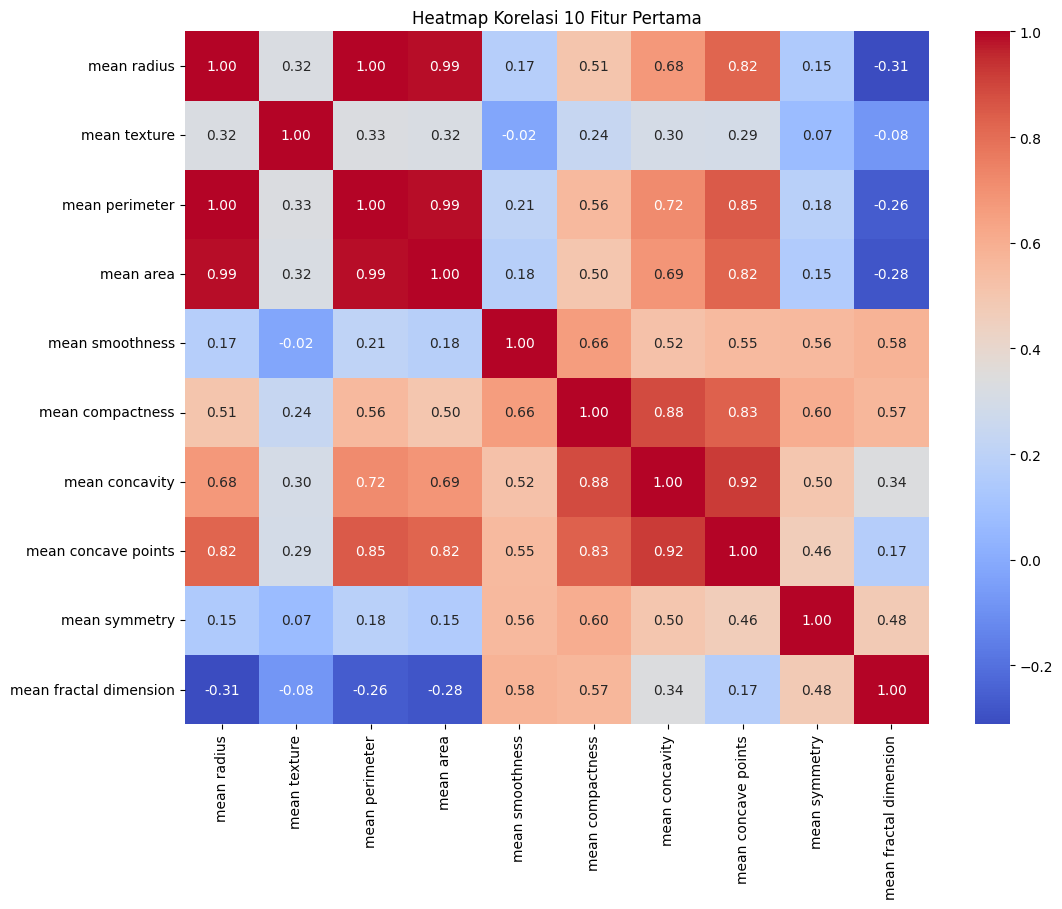

In [5]:
# Visualisasi 3: Heatmap korelasi
plt.figure(figsize=(12, 9))

correlation = df.corr()

sns.heatmap(
    correlation.iloc[:10, :10],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Heatmap Korelasi 10 Fitur Pertama')
plt.show()


**Interpretasi Visualisasi 3: Heatmap Korelasi**

Heatmap menunjukkan adanya korelasi positif yang sangat kuat antara `mean radius` dan `mean perimeter` sebesar 1,00, serta antara `mean radius` dan `mean area` sebesar 0,99. Selain itu, `mean concavity` dan `mean concave points` memiliki korelasi sebesar 0,92. Korelasi tinggi ini menunjukkan bahwa beberapa fitur memiliki informasi yang saling berkaitan. Kondisi tersebut perlu diperhatikan dalam pemilihan fitur karena dapat menyebabkan multikolinearitas.


### B3. Preprocessing

Pemeriksaan awal menunjukkan bahwa dataset tidak memiliki missing values maupun data duplikat. Seluruh fitur prediktor bertipe numerik sehingga encoding tidak diperlukan. Outlier akan diperiksa, tetapi tidak langsung dihapus karena dapat mengandung informasi penting. StandardScaler akan digunakan untuk menyamakan skala fitur sebelum pemodelan. Distribusi target juga diperhatikan karena jumlah kelas malignant dan benign tidak seimbang.

In [6]:
# Memisahkan fitur dan target
X = df.drop(columns=['target'])
y = df['target']

# Memeriksa outlier menggunakan metode IQR
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_count = (
    (X < (Q1 - 1.5 * IQR)) |
    (X > (Q3 + 1.5 * IQR))
).sum()

print("Jumlah missing values:", X.isnull().sum().sum())
print("Jumlah data duplikat:", df.duplicated().sum())

print("\nJumlah outlier pada 10 fitur pertama:")
print(outlier_count.head(10))


Jumlah missing values: 0
Jumlah data duplikat: 0

Jumlah outlier pada 10 fitur pertama:
mean radius               14
mean texture               7
mean perimeter            13
mean area                 25
mean smoothness            6
mean compactness          16
mean concavity            18
mean concave points       10
mean symmetry             15
mean fractal dimension    15
dtype: int64


### B4. Pemilihan Fitur

Sebanyak 30 fitur numerik dipertahankan sebagai prediktor, sedangkan `target` digunakan sebagai variabel yang akan diprediksi. Pemilihan ini dilakukan agar model dapat memanfaatkan berbagai karakteristik tumor. Berdasarkan heatmap, beberapa fitur memiliki korelasi yang sangat tinggi, seperti `mean radius` dan `mean perimeter`. Hal ini perlu diperhatikan karena dapat menyebabkan multikolinearitas.

In [7]:
# Menampilkan fitur yang digunakan
print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

print("\nDaftar fitur:")
print(X.columns.tolist())

print("\nDistribusi kelas target:")
print(y.value_counts().sort_index())


Jumlah fitur: 30
Jumlah data: 569

Daftar fitur:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Distribusi kelas target:
target
0    212
1    357
Name: count, dtype: int64


### B5. Pembagian Data

Dataset dibagi menjadi 80% data latih dan 20% data uji menggunakan `train_test_split`. Parameter `stratify=y` digunakan untuk menjaga proporsi kelas malignant dan benign pada data latih dan data uji. Parameter `random_state=42` digunakan agar pembagian data dapat direproduksi.

In [8]:
from sklearn.model_selection import train_test_split

# Membagi data dengan stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

print("\nDistribusi kelas data latih:")
print(y_train.value_counts().sort_index())

print("\nDistribusi kelas data uji:")
print(y_test.value_counts().sort_index())


Jumlah data latih: 455
Jumlah data uji: 114

Distribusi kelas data latih:
target
0    170
1    285
Name: count, dtype: int64

Distribusi kelas data uji:
target
0    42
1    72
Name: count, dtype: int64


### B6. Pemodelan Logistic Regression

Model Logistic Regression digunakan untuk mengklasifikasikan tumor menjadi dua kelas, yaitu malignant (ganas) dan benign (jinak). StandardScaler digunakan untuk menyamakan skala fitur numerik. Model dilatih menggunakan data latih, kemudian koefisiennya dianalisis untuk memahami hubungan fitur dengan peluang kelas positif (benign).

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Membuat pipeline scaling dan Logistic Regression
model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=5000))
])

# Melatih model
model.fit(X_train, y_train)

print("Model Logistic Regression berhasil dilatih!")

# Menampilkan koefisien setiap fitur
koefisien = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model.named_steps['logistic'].coef_[0]
})

print("\nKoefisien 10 fitur pertama:")
print(koefisien.head(10))

# Menampilkan intercept
print("\nIntercept:", model.named_steps['logistic'].intercept_[0])


Model Logistic Regression berhasil dilatih!

Koefisien 10 fitur pertama:
                    Fitur  Koefisien
0             mean radius  -0.511479
1            mean texture  -0.552698
2          mean perimeter  -0.476298
3               mean area  -0.541059
4         mean smoothness  -0.212479
5        mean compactness   0.648342
6          mean concavity  -0.602103
7     mean concave points  -0.704156
8           mean symmetry  -0.167233
9  mean fractal dimension   0.199732

Intercept: 0.30220757353702


### B7. Evaluasi Model

Evaluasi model dilakukan menggunakan accuracy, precision, recall, dan F1-score. Confusion matrix digunakan untuk melihat jumlah prediksi benar dan salah pada setiap kelas. Kurva ROC dan nilai AUC digunakan untuk menilai kemampuan model membedakan kelas malignant dan benign pada berbagai ambang klasifikasi.

Accuracy : 0.9824561403508771
Precision: 0.9861111111111112
Recall   : 0.9861111111111112
F1-score : 0.9861111111111112

Classification Report:
                   precision    recall  f1-score   support

Malignant (Ganas)       0.98      0.98      0.98        42
   Benign (Jinak)       0.99      0.99      0.99        72

         accuracy                           0.98       114
        macro avg       0.98      0.98      0.98       114
     weighted avg       0.98      0.98      0.98       114



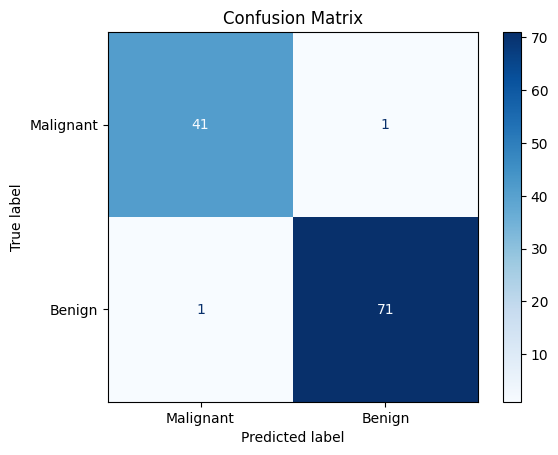

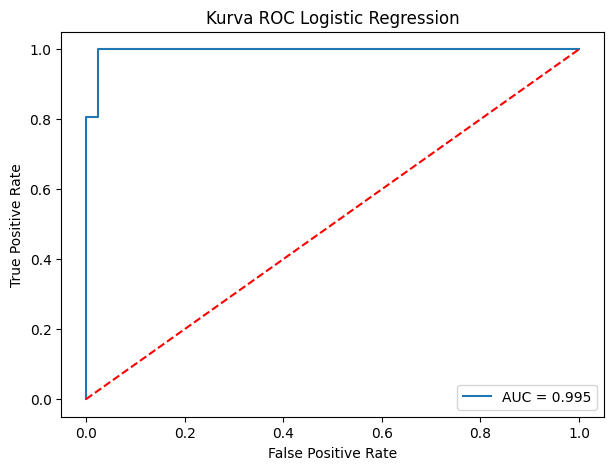

AUC: 0.9953703703703703


In [10]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, roc_auc_score, ConfusionMatrixDisplay
)

# Prediksi kelas dan probabilitas
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Menghitung metrik evaluasi
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Malignant (Ganas)', 'Benign (Jinak)']
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Malignant', 'Benign']
)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# Kurva ROC dan AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC Logistic Regression')
plt.legend()
plt.show()

print("AUC:", auc)


### B8. Analisis Performa

Model Logistic Regression memperoleh accuracy sebesar 98,25%, precision sebesar 98,61%, recall sebesar 98,61%, dan F1-score sebesar 98,61%. Nilai AUC sebesar 0,995 menunjukkan bahwa model memiliki kemampuan yang sangat baik dalam membedakan kelas malignant dan benign.

Berdasarkan confusion matrix, sebanyak 41 data malignant dan 71 data benign berhasil diklasifikasikan dengan benar. Terdapat satu data malignant yang salah diprediksi sebagai benign dan satu data benign yang salah diprediksi sebagai malignant.

Dalam kasus klasifikasi tumor, recall untuk kelas malignant penting diperhatikan karena kesalahan mengklasifikasikan tumor ganas sebagai jinak dapat berisiko. Model ini berhasil mengidentifikasi 41 dari 42 data malignant pada data uji. Meskipun performanya tinggi, model tetap memiliki keterbatasan dan hasil klasifikasinya tidak dapat menggantikan pemeriksaan serta diagnosis tenaga medis.